# Lesson 1a: Modelling tumour growth

**Goal:** build intuition for *mechanistic* models, where you write down how you think a system works
as equations, simulate it, and compare it to data.

The starting point is **first-order growth**: early on, every cell divides independently, so the
growth rate is proportional to the number of cells, the same kinetics as a bacterial culture in log
phase (or radioactive decay, with the sign flipped). The interesting science starts where that simple picture breaks.

What we'll do:
1. Exponential growth (first-order kinetics)
2. Limits to growth: logistic and Gompertz models
3. Adding a drug
4. Drug resistance: why tumours come back
5. Fitting a model to (noisy) data

Run each cell with Shift+Enter. Cells marked **Your turn** are for you to change and rerun.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

plt.rcParams["figure.figsize"] = (8, 4.5)
rng = np.random.default_rng(42)

## 1. Exponential growth

If every cell divides at rate *r* per day, the number of cells *N* follows

$$\frac{dN}{dt} = rN \quad\Rightarrow\quad N(t) = N_0 e^{rt}$$

A first-order process: the doubling time is $\ln 2 / r$, the mirror image of a half-life.

Doubling time: 8.7 days


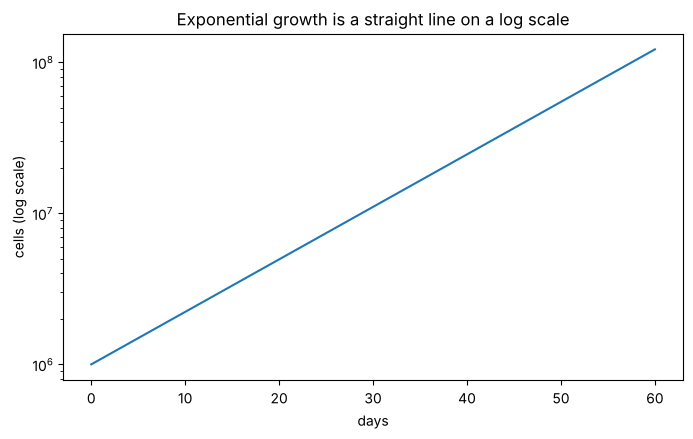

In [2]:
t = np.linspace(0, 60, 300)          # days
N0, r = 1e6, 0.08                     # one million cells, 8% growth per day
N = N0 * np.exp(r * t)

print(f"Doubling time: {np.log(2) / r:.1f} days")
plt.plot(t, N)
plt.yscale("log")
plt.xlabel("days"); plt.ylabel("cells (log scale)")
plt.title("Exponential growth is a straight line on a log scale")
plt.show()

## 2. Limits to growth

Real tumours slow down: they run out of space, oxygen and nutrients. Two classic models:

- **Logistic:** $\frac{dN}{dt} = rN\left(1 - \frac{N}{K}\right)$, growth stops at a carrying capacity *K*.
- **Gompertz:** $\frac{dN}{dt} = rN \ln\frac{K}{N}$, growth slows down earlier and more gradually. It often fits real tumour data better.

Mathematically these are first-order ODEs (ordinary differential equations). We'll solve them numerically
with `solve_ivp`, the same way you'd simulate any dynamic system.

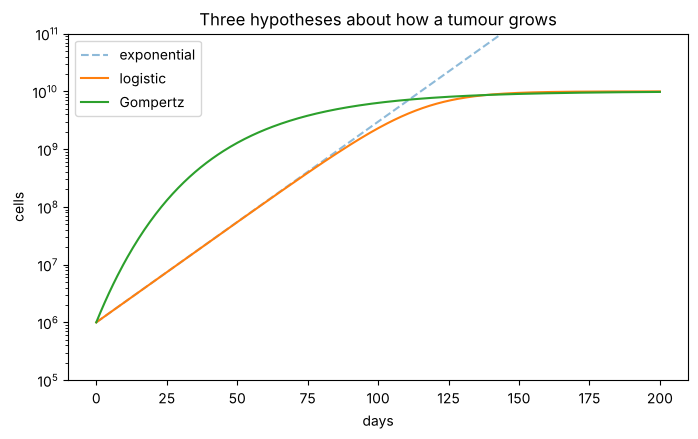

In [3]:
K = 1e10   # carrying capacity

def logistic(t, N, r, K):
    return r * N * (1 - N / K)

def gompertz(t, N, r, K):
    return r * N * np.log(K / N)

span, t_eval = (0, 200), np.linspace(0, 200, 400)
log_sol = solve_ivp(logistic, span, [N0], args=(0.08, K), t_eval=t_eval)
gom_sol = solve_ivp(gompertz, span, [N0], args=(0.03, K), t_eval=t_eval)

plt.plot(t_eval, N0 * np.exp(0.08 * t_eval), "--", label="exponential", alpha=0.5)
plt.plot(log_sol.t, log_sol.y[0], label="logistic")
plt.plot(gom_sol.t, gom_sol.y[0], label="Gompertz")
plt.yscale("log"); plt.ylim(1e5, 1e11)
plt.xlabel("days"); plt.ylabel("cells"); plt.legend()
plt.title("Three hypotheses about how a tumour grows")
plt.show()

**Your turn:** change *r* for the Gompertz model (e.g. 0.01, 0.05). How does it change *when* the
tumour reaches half its maximum size? Why might that matter for when a tumour is detected?

## 3. Adding a drug

A simple way to model a cytotoxic drug: it kills a fraction of cells per day while it's present.

$$\frac{dN}{dt} = rN\ln\frac{K}{N} - d(t)\,N$$

where $d(t)$ is the kill rate, non-zero only during treatment. Below: treatment from day 60 to day 120.

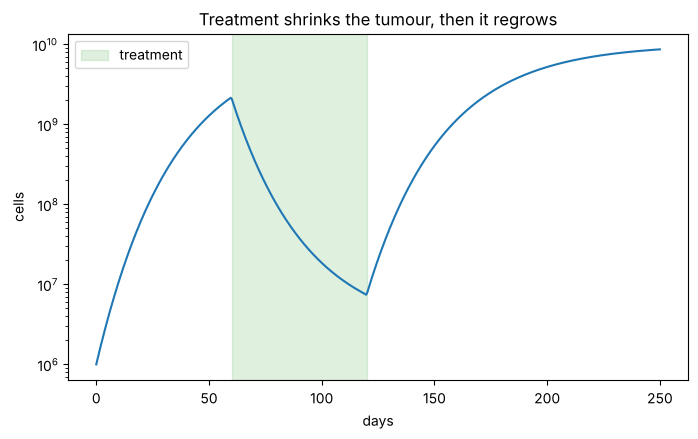

In [4]:
def with_drug(t, N, r, K, kill, start, stop):
    d = kill if start <= t <= stop else 0.0
    return r * N * np.log(K / N) - d * N

sol = solve_ivp(with_drug, (0, 250), [N0], args=(0.03, K, 0.25, 60, 120),
                t_eval=np.linspace(0, 250, 500), max_step=0.5)

plt.plot(sol.t, sol.y[0])
plt.axvspan(60, 120, color="tab:green", alpha=0.15, label="treatment")
plt.yscale("log"); plt.xlabel("days"); plt.ylabel("cells"); plt.legend()
plt.title("Treatment shrinks the tumour, then it regrows")
plt.show()

## 4. Resistance: two populations

Most tumours are not one population. Suppose a small fraction of cells (say 1 in 10,000) is
**resistant**: the drug barely touches them. Both populations share the same space (same *K*).
Think of it as a mixed population where a tiny minority responds completely differently under stress.

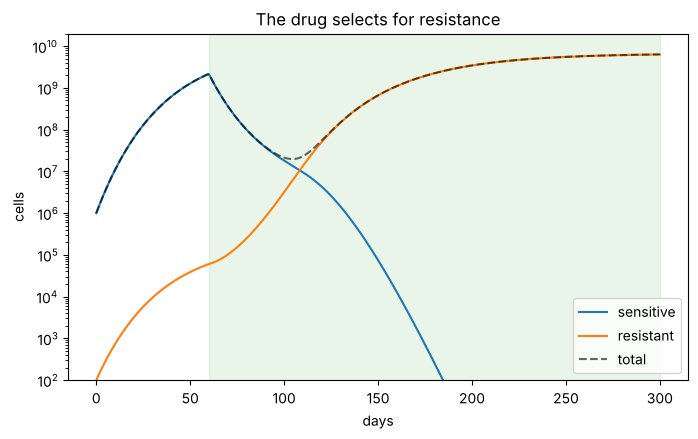

total at day 300: 6.35e+09


In [5]:
def dose_at(t, schedule):
    for start, stop, kill in schedule:
        if start <= t <= stop:
            return kill
    return 0.0

def two_pop(t, y, r_s, r_r, K, schedule):
    S, R = y
    growth = np.log(K / (S + R))
    kill_s = dose_at(t, schedule)
    kill_r = 0.04 * kill_s          # resistant cells feel only 4% of the dose
    return [r_s * S * growth - kill_s * S,
            r_r * R * growth - kill_r * R]

# treatment windows: (start day, stop day, kill rate on sensitive cells per day)
schedule = [(60, 300, 0.25)]        # continuous high dose from day 60

y0 = [N0 * (1 - 1e-4), N0 * 1e-4]
# resistant cells grow a little slower (resistance often has a fitness cost)
sol = solve_ivp(two_pop, (0, 300), y0, args=(0.03, 0.025, K, schedule),
                t_eval=np.linspace(0, 300, 600), max_step=0.5)

plt.plot(sol.t, sol.y[0], label="sensitive")
plt.plot(sol.t, sol.y[1], label="resistant")
plt.plot(sol.t, sol.y.sum(0), "k--", label="total", alpha=0.6)
for start, stop, kill in schedule:
    plt.axvspan(start, stop, color="tab:green", alpha=0.1)
plt.yscale("log"); plt.ylim(1e2, 2e10)
plt.xlabel("days"); plt.ylabel("cells"); plt.legend()
plt.title("The drug selects for resistance")
plt.show()
print(f"total at day 300: {sol.y[:, -1].sum():.2e}")

This is the logic behind real research questions, such as **adaptive therapy**: instead of
maximum dose, treat on and off to keep sensitive cells around, because they compete with the
resistant ones for space (this is called *competitive release* when it goes wrong).

**Your turn:** design a better treatment by editing only the `schedule` list. You can add as many
`(start, stop, dose)` windows as you like, anywhere between day 0 and day 300, with any dose.
The simulation always runs to day 300 and prints the total tumour size there: that's your score.

- **Baseline to beat:** the continuous high dose above, about 6.4e9 cells at day 300.
- **Bonus:** finish with more sensitive than resistant cells, so the drug still works next time.
- Ideas to try: a lower constant dose; several short pulses; a high dose followed by a low maintenance dose.

## 5. Fitting a model to data

Science runs the other way too: you have measurements and want the parameters. Here we make
fake measurements from a Gompertz tumour, add 15% noise (like real caliper measurements in mice),
and see if we can recover *r* and *K*.

r:      true 0.03,  fitted 0.0279 ± 0.0010
log10K: true 10,  fitted 10.07 ± 0.02


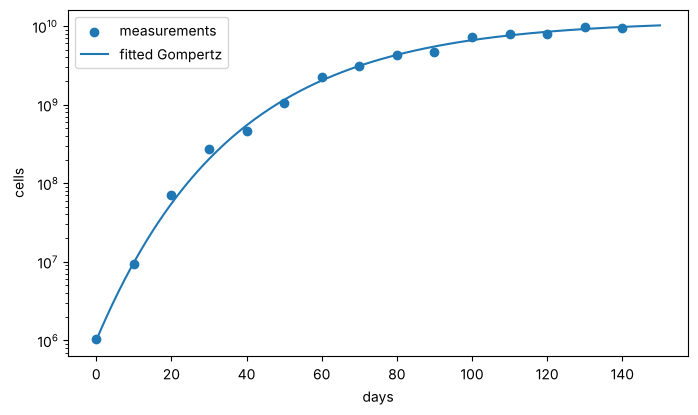

In [6]:
def gompertz_closed(t, r, logK):
    K = 10 ** logK
    return K * np.exp(np.log(N0 / K) * np.exp(-r * t))

t_obs = np.arange(0, 150, 10)
true_r, true_logK = 0.03, 10
obs = gompertz_closed(t_obs, true_r, true_logK) * rng.lognormal(0, 0.15, t_obs.size)

params, cov = curve_fit(gompertz_closed, t_obs, obs, p0=[0.05, 9.5])
err = np.sqrt(np.diag(cov))
print(f"r:      true {true_r},  fitted {params[0]:.4f} ± {err[0]:.4f}")
print(f"log10K: true {true_logK},  fitted {params[1]:.2f} ± {err[1]:.2f}")

tt = np.linspace(0, 150, 300)
plt.scatter(t_obs, obs, label="measurements", zorder=3)
plt.plot(tt, gompertz_closed(tt, *params), label="fitted Gompertz")
plt.yscale("log"); plt.xlabel("days"); plt.ylabel("cells"); plt.legend()
plt.show()

## Recap and reflection

- Mechanistic models turn a hypothesis ("resistant cells pre-exist") into something you can simulate and test.
- The maths is general: growth rates, first-order kinetics, mixtures of sub-populations, parameter fitting under noise.
- Real research versions add space (where cells are), the immune system, pharmacokinetics (how drug levels change in the body) and stochasticity (randomness when cell numbers are small).

**Questions to think about:**
1. Which growth law would you expect to fit a fast-growing leukaemia best, and why?
2. What extra ingredient would you add to the resistance model to make it more realistic?

Next: **Lesson 1b** uses real-world style data to find genes cancer cells depend on.